# Regression: Age, Height and Lung Capacity

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Explore linear relationships and predict continuous outcomes from explanatory variables.

**Approach:** Exploratory plots and regression analysis in Python.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>TP : Regression</span>
    </span>
    </center>
<br>


### GUERBOUZ MOHAMMED ALAA EDDINE
# Execice 01


### Step 1: Load the Data
The data is loaded from a file named `DataHeight.txt` using pandas. The file is assumed to be tab-delimited.

```python
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

In [17]:
# Step 1: Load the data
tab = pd.read_csv('DataHeight.txt', delimiter='\t')  # Adjust the delimiter if needed
print(tab.head())  # Preview the data

   index       age    height
0      1  2.065875  0.779189
1      2  2.368409  0.915968
2      3  2.539993  0.905384
3      4  2.542080  0.905661
4      5  2.549079  0.938989


### Step 2: Extract the Columns
The columns for age and height are extracted from the dataset.

In [18]:
# Step 2: Extract the columns
x = tab['age']  # Age column
y = tab['height']  # Height column

### Step 3: Plot the Data
A scatter plot is created to visualize the relationship between age and height.

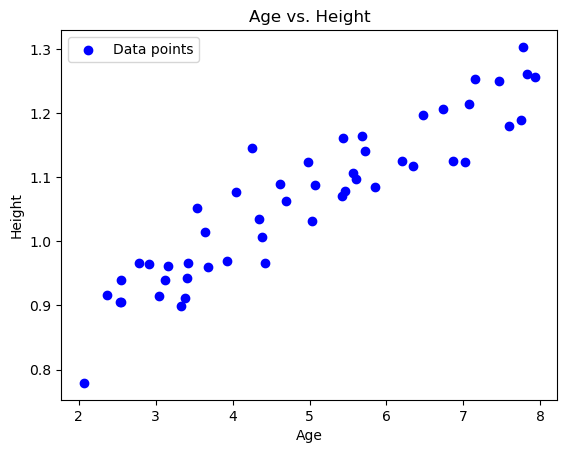

In [19]:
# Step 3: Plot the data
plt.scatter(x, y, color='blue', label='Data points')
plt.xlabel('Age')
plt.ylabel('Height')
plt.title('Age vs. Height')
plt.legend()
plt.show()

### Step 4: Analyze Correlation
The correlation coefficient between age and height is calculated to understand the strength and direction of their relationship.

In [20]:
# Steps 4 & 5: Analyze correlation
correlation = np.corrcoef(x, y)[0, 1]
print(f"Correlation coefficient: {correlation}")

# Interpretation
if correlation > 0.5:
    print("There seems to be a positive correlation between age and height.")
elif correlation < -0.5:
    print("There seems to be a negative correlation between age and height.")
else:
    print("There seems to be little to no correlation.")


Correlation coefficient: 0.9263170211762402
There seems to be a positive correlation between age and height.


### Step 5: Perform Linear Regression
Linear regression is performed to model the relationship between age and height.

### Step 6: Residual Analysis
The residuals (differences between observed and predicted values) are calculated and analyzed.

In [21]:
# Step 6: Perform linear regression
slope, intercept, r_value, p_value, std_err = linregress(x, y)

print(f"Slope (θ1): {slope}")
print(f"Intercept (θ0): {intercept}")
print(f"Residual standard error: {std_err}")

Slope (θ1): 0.0638811658258342
Intercept (θ0): 0.7501625370012386
Residual standard error: 0.003750075737402295


### Step 7: Regression Equation
The regression equation is printed, which can be used to predict height based on age.

In [22]:
# Step 7: Residual analysis
predicted_y = intercept + slope * x
residuals = y - predicted_y
residual_sum_of_squares = np.sum(residuals**2)
print(f"Residual Sum of Squares (RSS): {residual_sum_of_squares}")

Residual Sum of Squares (RSS): 0.0987069973276125


### Step 8: Plot the Regression Line
The regression line is plotted over the scatter plot to visualize the model.

The regression equation is: height = 0.75 + 0.06 * age


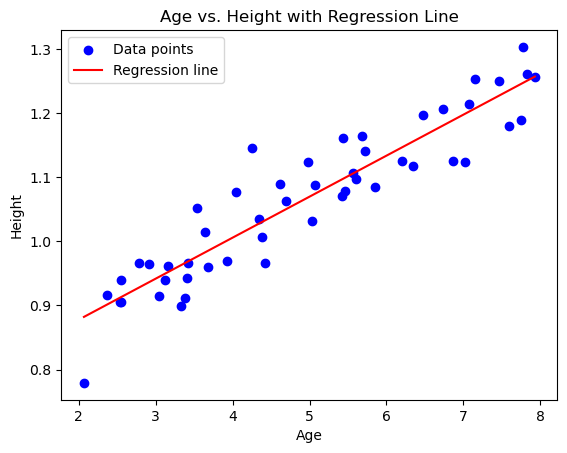

In [23]:
# Step 8: Regression equation
print(f"The regression equation is: height = {intercept:.2f} + {slope:.2f} * age")

# Step 9: Plot the regression line
plt.scatter(x, y, color='blue', label='Data points')
plt.plot(x, predicted_y, color='red', label='Regression line')
plt.xlabel('Age')
plt.ylabel('Height')
plt.title('Age vs. Height with Regression Line')
plt.legend()
plt.show()

### Step 9: Predict Heights
The model is used to predict heights for specific ages.

In [24]:
ages_to_predict = [3, 7, 9, 12]
predicted_heights = [intercept + slope * age for age in ages_to_predict]
for age, height in zip(ages_to_predict, predicted_heights):
    print(f"Predicted height for age {age}: {height:.2f}")


Predicted height for age 3: 0.94
Predicted height for age 7: 1.20
Predicted height for age 9: 1.33
Predicted height for age 12: 1.52


###Step 10: Confidence Interval for a Prediction
A confidence interval is calculated for a specific prediction to understand the uncertainty.

In [25]:
# Step 10: Confidence interval for a prediction
from scipy.stats import t
n = len(x)
mean_x = np.mean(x)
t_critical = t.ppf(0.975, df=n-2)  # 95% confidence

In [26]:
# Function to calculate prediction interval
def prediction_interval(x0, intercept, slope, std_err, mean_x, n, t_critical):
    se = std_err * np.sqrt(1/n + (x0 - mean_x)**2 / np.sum((x - mean_x)**2))
    margin_of_error = t_critical * se
    prediction = intercept + slope * x0
    return prediction - margin_of_error, prediction + margin_of_error

x0 = 10  # Predicting for age 10
lower, upper = prediction_interval(x0, intercept, slope, std_err, mean_x, n, t_critical)
print(f"Predicted height for age {x0} with 95% confidence interval: {lower:.2f} to {upper:.2f}")

Predicted height for age 10 with 95% confidence interval: 1.39 to 1.39


# Execice 02

### Step 1: Load the Data
The data is loaded from a file named LungCapData.txt using pandas.

In [27]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
import seaborn as sns
import matplotlib.pyplot as plt

In [28]:
# Step 1: Load the data
# Replace 'file_path' with the actual file path to your dataset
file_path = "LungCapData.txt"  
data = pd.read_csv(file_path, sep="\t")  # Assuming the file is tab-separated


### Step 2: Explore the Data
The column names, data types, and unique levels of the 'Smoke' column are explored.

In [29]:
# Step 2: Explore the data
print("Column Names:", data.columns)
print("Data Types:\n", data.dtypes)
print("Unique Levels of 'Smoke':", data['Smoke'].unique())

Column Names: Index(['LungCap', 'Age', 'Height', 'Smoke', 'Gender', 'Caesarean'], dtype='object')
Data Types:
 LungCap      float64
Age            int64
Height       float64
Smoke         object
Gender        object
Caesarean     object
dtype: object
Unique Levels of 'Smoke': ['no' 'yes']


### Step 3: Regression Model 1
A regression model is created to predict LungCap based on Age and Height.

In [30]:
# Step 3: Regression Model 1
# Model: LungCap ~ Age + Height
model1 = ols("LungCap ~ Age + Height", data=data).fit()
print("\nModel 1 Summary:\n", model1.summary())


Model 1 Summary:
                             OLS Regression Results                            
Dep. Variable:                LungCap   R-squared:                       0.843
Model:                            OLS   Adj. R-squared:                  0.843
Method:                 Least Squares   F-statistic:                     1938.
Date:                Sat, 25 Jan 2025   Prob (F-statistic):          5.44e-291
Time:                        15:30:20   Log-Likelihood:                -1066.9
No. Observations:                 725   AIC:                             2140.
Df Residuals:                     722   BIC:                             2154.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -11.7471      0.477 

### Step 4: Correlation Between Age and Height
The correlation between Age and Height is calculated to understand their relationship.

In [31]:
# Step 4: Correlation Between Age and Height
correlation = data[['Age', 'Height']].corr(method="pearson")
print("\nCorrelation Between Age and Height:\n", correlation)


Correlation Between Age and Height:
              Age    Height
Age     1.000000  0.835737
Height  0.835737  1.000000


### Step 5: Regression Model 2
A more complex regression model is created to predict LungCap based on Age, Height, Smoke, Gender, and Caesarean.

In [32]:
# Step 5: Regression Model 2
# Model: LungCap ~ Age + Height + Smoke + Gender + Caesarean
model2 = ols("LungCap ~ Age + Height + Smoke + Gender + Caesarean", data=data).fit()
print("\nModel 2 Summary:\n", model2.summary())



Model 2 Summary:
                             OLS Regression Results                            
Dep. Variable:                LungCap   R-squared:                       0.854
Model:                            OLS   Adj. R-squared:                  0.853
Method:                 Least Squares   F-statistic:                     842.8
Date:                Sat, 25 Jan 2025   Prob (F-statistic):          8.50e-298
Time:                        15:30:21   Log-Likelihood:                -1039.9
No. Observations:                 725   AIC:                             2092.
Df Residuals:                     719   BIC:                             2119.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          -1

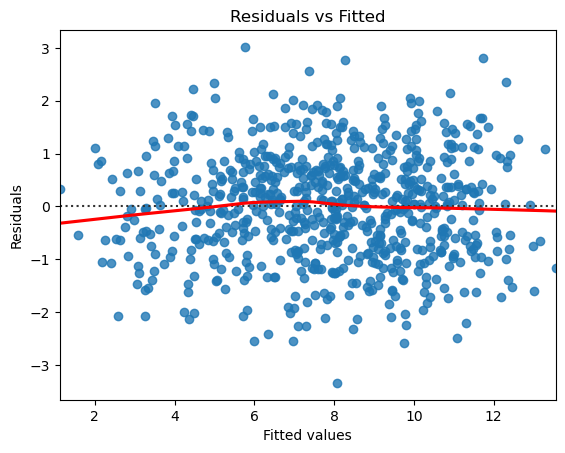

In [33]:

# Step 6: Plot Residuals for Model 2
sns.residplot(x=model2.fittedvalues, y=model2.resid, lowess=True, line_kws={"color": "red"})
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")
plt.show()

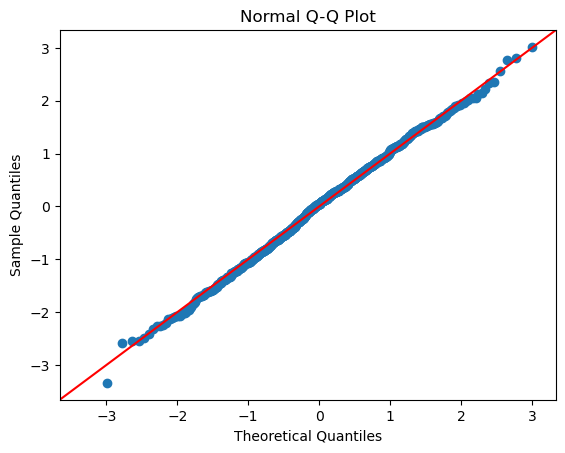

In [34]:
# Step 7: Diagnostic Plots for Model 2
# QQ Plot
sm.qqplot(model2.resid, line="45")
plt.title("Normal Q-Q Plot")
plt.show()

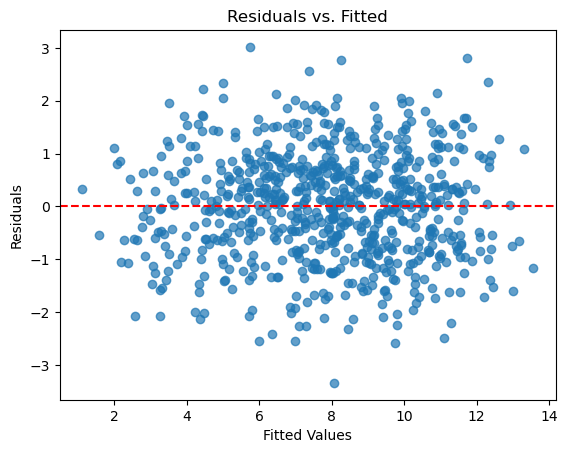

In [35]:
# Residuals vs. Fitted Plot
plt.scatter(model2.fittedvalues, model2.resid, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs. Fitted")
plt.show()